# Audio Anomaly Detection - Isolation Forest (Enhanced)
**Improvements:** Multi-feature extraction, augmentation, feature scaling, hyperparameter tuning, cross-validation

In [1]:
import os, numpy as np, librosa, librosa.display, joblib, warnings
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')
print('All libraries imported!')

All libraries imported!


In [2]:
AUDIO_DATASET = r'd:\multimodel-surveillence\DATASET\dataset.audio'
NORMAL_DIR = os.path.join(AUDIO_DATASET, 'normal')
ANOMALY_DIR = os.path.join(AUDIO_DATASET, 'anomoly')
normal_files = [f for f in os.listdir(NORMAL_DIR) if f.endswith('.wav')] if os.path.exists(NORMAL_DIR) else []
anomaly_files = [f for f in os.listdir(ANOMALY_DIR) if f.endswith('.wav')] if os.path.exists(ANOMALY_DIR) else []
print(f'Normal: {len(normal_files)} files, Anomaly: {len(anomaly_files)} files')

Normal: 3 files, Anomaly: 3 files


## Enhanced Feature Extraction (384 dimensions)
MFCC + Spectral Contrast + Chroma + ZCR + Centroid + Bandwidth + Rolloff + RMS + Mel Spectrogram

In [3]:
def extract_features_enhanced(file_path, n_mfcc=40):
    try:
        y, sr = librosa.load(file_path, duration=30)
        feat = []
        mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc)
        feat.extend(np.mean(mfccs.T, axis=0)); feat.extend(np.std(mfccs.T, axis=0))
        sc = librosa.feature.spectral_contrast(y=y, sr=sr)
        feat.extend(np.mean(sc.T, axis=0)); feat.extend(np.std(sc.T, axis=0))
        chroma = librosa.feature.chroma_stft(y=y, sr=sr)
        feat.extend(np.mean(chroma.T, axis=0)); feat.extend(np.std(chroma.T, axis=0))
        for fn in [librosa.feature.zero_crossing_rate, lambda y=y: librosa.feature.spectral_centroid(y=y, sr=sr),
                   lambda y=y: librosa.feature.spectral_bandwidth(y=y, sr=sr),
                   lambda y=y: librosa.feature.spectral_rolloff(y=y, sr=sr),
                   lambda y=y: librosa.feature.rms(y=y)]:
            try:
                r = fn(y) if 'zero' in str(fn) else fn()
            except: r = fn(y=y)
            feat.append(np.mean(r)); feat.append(np.std(r))
        mel = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128), ref=np.max)
        feat.extend(np.mean(mel.T, axis=0)); feat.extend(np.std(mel.T, axis=0))
        return np.array(feat)
    except Exception as e:
        print(f'Error: {file_path}: {e}')
        return None

## Audio Augmentation (noise, time-stretch, pitch-shift, volume, crop)

In [4]:
def augment_and_extract(file_path, n_augments=10):
    results = []
    try: y, sr = librosa.load(file_path, duration=30)
    except: return []
    for i in range(n_augments):
        ya = y.copy()
        t = i % 5
        if t==0: ya = ya + np.random.randn(len(ya))*0.005
        elif t==1: ya = librosa.effects.time_stretch(ya, rate=np.random.uniform(0.8,1.2))
        elif t==2: ya = librosa.effects.pitch_shift(ya, sr=sr, n_steps=np.random.uniform(-2,2))
        elif t==3: ya = ya * np.random.uniform(0.7,1.3)
        elif t==4:
            s=np.random.randint(0,max(1,len(ya)//4)); ya=ya[s:s+int(len(ya)*0.75)]
        try:
            feat = []
            mfccs = librosa.feature.mfcc(y=ya, sr=sr, n_mfcc=40)
            feat.extend(np.mean(mfccs.T,axis=0)); feat.extend(np.std(mfccs.T,axis=0))
            sc = librosa.feature.spectral_contrast(y=ya, sr=sr)
            feat.extend(np.mean(sc.T,axis=0)); feat.extend(np.std(sc.T,axis=0))
            ch = librosa.feature.chroma_stft(y=ya, sr=sr)
            feat.extend(np.mean(ch.T,axis=0)); feat.extend(np.std(ch.T,axis=0))
            for fn_name in ['zero_crossing_rate','spectral_centroid','spectral_bandwidth','spectral_rolloff','rms']:
                fn = getattr(librosa.feature, fn_name)
                r = fn(y=ya) if fn_name in ['zero_crossing_rate','rms'] else fn(y=ya, sr=sr)
                feat.append(np.mean(r)); feat.append(np.std(r))
            mel = librosa.power_to_db(librosa.feature.melspectrogram(y=ya, sr=sr, n_mels=128), ref=np.max)
            feat.extend(np.mean(mel.T,axis=0)); feat.extend(np.std(mel.T,axis=0))
            results.append(np.array(feat))
        except: pass
    return results

## Load, Augment & Extract All Features

In [5]:
features, labels, fnames = [], [], []
N_AUG = 10
for file in normal_files:
    fp = os.path.join(NORMAL_DIR, file)
    f = extract_features_enhanced(fp)
    if f is not None: features.append(f); labels.append(1); fnames.append(file)
    for af in augment_and_extract(fp, N_AUG): features.append(af); labels.append(1); fnames.append(f'{file}_aug')
    print(f'  Normal: {file} + {N_AUG} augmented')
for file in anomaly_files:
    fp = os.path.join(ANOMALY_DIR, file)
    f = extract_features_enhanced(fp)
    if f is not None: features.append(f); labels.append(-1); fnames.append(file)
    for af in augment_and_extract(fp, N_AUG): features.append(af); labels.append(-1); fnames.append(f'{file}_aug')
    print(f'  Anomaly: {file} + {N_AUG} augmented')
X = np.array(features); y = np.array(labels)
print(f'\nTotal samples: {len(X)}, Features: {X.shape[1]}, Normal: {np.sum(y==1)}, Anomaly: {np.sum(y==-1)}')

  Normal: man-laughing.wav + 10 augmented
  Normal: people-in-lounge.wav + 10 augmented
  Normal: spring-weather.wav + 10 augmented
  Anomaly: ambulance-siren.wav + 10 augmented
  Anomaly: explosion.wav + 10 augmented
  Anomaly: glass-shattering.wav + 10 augmented

Total samples: 66, Features: 384, Normal: 33, Anomaly: 33


## Feature Scaling & Train/Test Split

In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.25, random_state=42, stratify=y)
print(f'Train: {len(X_train)} (Normal:{np.sum(y_train==1)}, Anomaly:{np.sum(y_train==-1)})')
print(f'Test:  {len(X_test)} (Normal:{np.sum(y_test==1)}, Anomaly:{np.sum(y_test==-1)})')

Train: 49 (Normal:25, Anomaly:24)
Test:  17 (Normal:8, Anomaly:9)


## Hyperparameter Tuning

In [7]:
best_f1, best_params = 0, {}
print(f'{"Cont":<8} {"N_Est":<8} {"Acc":<10} {"F1":<10}')
print('-'*36)
for cont in [0.05,0.1,0.15,0.2,0.25,0.3,0.35,0.4,0.45,0.5]:
    for n_est in [100,200,300]:
        m = IsolationForest(n_estimators=n_est, contamination=cont, random_state=42, n_jobs=-1)
        m.fit(X_train); p = m.predict(X_test)
        acc = accuracy_score(y_test, p); f1 = f1_score(y_test, p, pos_label=-1)
        print(f'{cont:<8.2f} {n_est:<8} {acc:<10.4f} {f1:<10.4f}')
        if f1 > best_f1: best_f1=f1; best_params={'contamination':cont,'n_estimators':n_est}
print(f'\nBest: {best_params}, F1={best_f1:.4f}')

Cont     N_Est    Acc        F1        
------------------------------------
0.05     100      0.5882     0.3636    
0.05     200      0.5882     0.3636    
0.05     300      0.5882     0.3636    
0.10     100      0.6471     0.5000    
0.10     200      0.6471     0.5000    
0.10     300      0.6471     0.5000    
0.15     100      0.8235     0.8000    
0.15     200      0.7059     0.6154    
0.15     300      0.7647     0.7143    
0.20     100      0.8235     0.8000    
0.20     200      0.7647     0.7143    
0.20     300      0.8235     0.8000    
0.25     100      0.8235     0.8000    
0.25     200      0.8235     0.8000    
0.25     300      0.8235     0.8000    
0.30     100      0.8235     0.8000    
0.30     200      0.8235     0.8000    
0.30     300      0.8235     0.8000    
0.35     100      0.8235     0.8000    
0.35     200      0.8235     0.8000    
0.35     300      0.8235     0.8000    
0.40     100      0.8824     0.8750    
0.40     200      0.8235     0.8000    
0.4

## Train Final Model & Cross-Validate

In [8]:
iso_forest = IsolationForest(**best_params, random_state=42, n_jobs=-1)
iso_forest.fit(X_train)
# Cross-validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_acc, cv_f1 = [], []
for fold,(ti,vi) in enumerate(skf.split(X_scaled, y)):
    cm = IsolationForest(**best_params, random_state=42, n_jobs=-1)
    cm.fit(X_scaled[ti]); cp = cm.predict(X_scaled[vi])
    cv_acc.append(accuracy_score(y[vi],cp)); cv_f1.append(f1_score(y[vi],cp,pos_label=-1))
    print(f'Fold {fold+1}: Acc={cv_acc[-1]:.4f}, F1={cv_f1[-1]:.4f}')
print(f'\nCV Accuracy: {np.mean(cv_acc):.4f} ± {np.std(cv_acc):.4f}')
print(f'CV F1:       {np.mean(cv_f1):.4f} ± {np.std(cv_f1):.4f}')

Fold 1: Acc=0.5000, F1=0.5333
Fold 2: Acc=0.6923, F1=0.5000
Fold 3: Acc=0.8462, F1=0.8571
Fold 4: Acc=0.8462, F1=0.8571
Fold 5: Acc=0.7692, F1=0.7692

CV Accuracy: 0.7308 ± 0.1287
CV F1:       0.7034 ± 0.1561


## Final Evaluation

In [9]:
test_preds = iso_forest.predict(X_test)
test_acc = accuracy_score(y_test, test_preds)
test_f1 = f1_score(y_test, test_preds, pos_label=-1)
print('='*50)
print('ISOLATION FOREST - FINAL RESULTS')
print('='*50)
print(f'Test Accuracy: {test_acc*100:.2f}%')
print(f'Test F1 Score: {test_f1*100:.2f}%')
print('\n--- Classification Report ---')
print(classification_report(y_test, test_preds, target_names=['Anomaly','Normal']))

ISOLATION FOREST - FINAL RESULTS
Test Accuracy: 88.24%
Test F1 Score: 88.89%

--- Classification Report ---
              precision    recall  f1-score   support

     Anomaly       0.89      0.89      0.89         9
      Normal       0.88      0.88      0.88         8

    accuracy                           0.88        17
   macro avg       0.88      0.88      0.88        17
weighted avg       0.88      0.88      0.88        17



## Confusion Matrix & Score Distribution

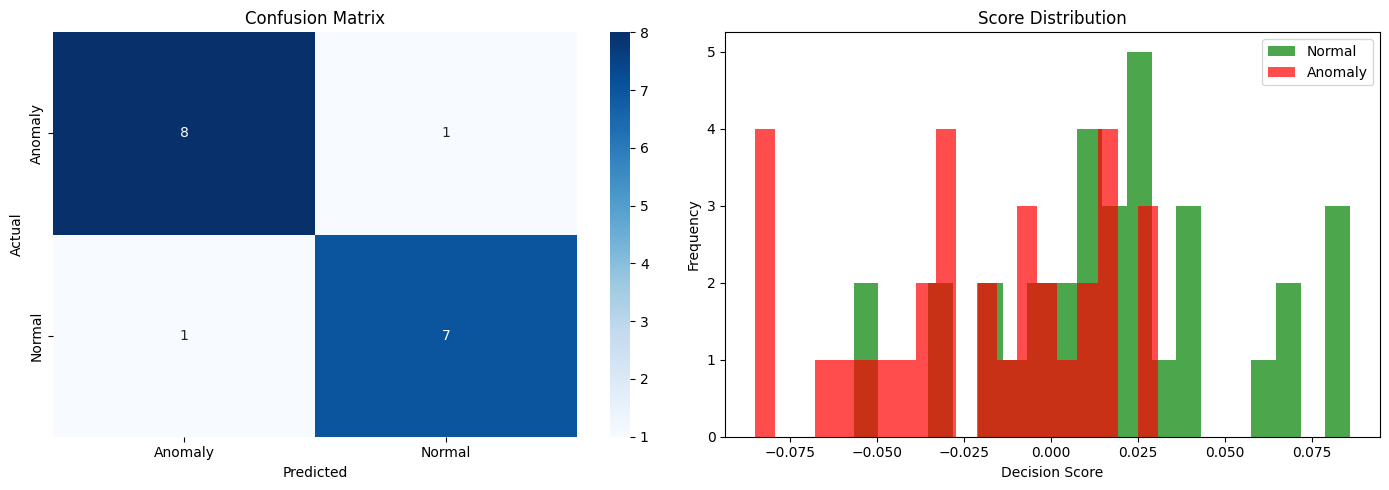

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
cm = confusion_matrix(y_test, test_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Anomaly','Normal'], yticklabels=['Anomaly','Normal'], ax=ax1)
ax1.set_title('Confusion Matrix'); ax1.set_ylabel('Actual'); ax1.set_xlabel('Predicted')
scores = iso_forest.decision_function(X_scaled)
ax2.hist(scores[y==1], bins=20, alpha=0.7, label='Normal', color='green')
ax2.hist(scores[y==-1], bins=20, alpha=0.7, label='Anomaly', color='red')
ax2.set_xlabel('Decision Score'); ax2.set_ylabel('Frequency'); ax2.set_title('Score Distribution'); ax2.legend()
plt.tight_layout(); plt.show()

## Save Model & Summary

In [11]:
joblib.dump(iso_forest, r'd:\multimodel-surveillence\audio_isolation_forest.pkl')
joblib.dump(scaler, r'd:\multimodel-surveillence\audio_scaler.pkl')
print('='*60)
print('    AUDIO DATASET VALIDATION SUMMARY (ENHANCED)')
print('='*60)
print(f'  Original files:     {len(normal_files)+len(anomaly_files)}')
print(f'  After augmentation: {len(X)}')
print(f'  Feature dims:       {X.shape[1]}')
print(f'  Best params:        {best_params}')
print(f'  Test accuracy:      {test_acc*100:.2f}%')
print(f'  Test F1:            {test_f1*100:.2f}%')
print(f'  CV accuracy (mean): {np.mean(cv_acc)*100:.2f}%')
print('='*60)
if test_acc>=0.8: print('  ✅ Dataset GOOD')
elif test_acc>=0.5: print('  ⚠️ Dataset FAIR')
else: print('  ❌ Needs improvement')
print('='*60)

    AUDIO DATASET VALIDATION SUMMARY (ENHANCED)
  Original files:     6
  After augmentation: 66
  Feature dims:       384
  Best params:        {'contamination': 0.45, 'n_estimators': 200}
  Test accuracy:      88.24%
  Test F1:            88.89%
  CV accuracy (mean): 73.08%
  ✅ Dataset GOOD
